# Student Participation and Academic Achievement Prediction
**PAS Course Project – Group 3A6 (A Division, Batch 3)** &nbsp;|&nbsp; Guide: Mr. Rajkumar V. Patil

| GR No | Roll No | Name |
|---|---|---|
| 1251080091 | 2080166 | Jiteesh Prashant Ghodke |
| 1251080081 | 2080159 | Kaustubh Rajkumar Gawali |
| 1251080122 | 2080152 | Himanshu Pushparaj Gaikwad |
| 1251080260 | 2080167 | Sparsh Sandip Zalwade |

**Problem statement:** Does a student's participation in studies (attendance, weekly study time, extra-curricular activities, past failures, wish to go for higher education) affect their final grade? We test this with statistics and build regression models to predict the final grade.

**How this notebook follows the requirement sheet**

| Requirement | Section |
|---|---|
| Dataset (100+ observations) | 1 |
| Sampling (method, size, bias) | 2 |
| Descriptive analysis (mean, median, SD, IQR, visualizations) | 3 |
| Confidence interval (95%) | 4 |
| Hypothesis testing (Z / t test, ANOVA) | 5 |
| Correlation (Pearson / Spearman) | 6 |
| Regression (SLR + MLR) | 7 |
| Model evaluation (MAE, MSE, RMSE, R²) | 8 |
| Prediction on held-out test set | 9 |
| Interpretation | 10 |
| What we did not do and why | 11 |

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import statsmodels.api as sm
from statsmodels.stats.stattools import durbin_watson
from statsmodels.stats.outliers_influence import variance_inflation_factor
import warnings
warnings.filterwarnings('ignore')

## 1. Dataset
> *Requirement: preferably 100+ relevant observations.*

**Where we got it:** UCI Machine Learning Repository – *Student Performance* dataset
(P. Cortez and A. Silva, 2008) – https://archive.ics.uci.edu/dataset/320/student+performance

- Real data collected from 2 secondary schools in Portugal (Gabriel Pereira = GP, Mousinho da Silveira = MS) using school reports and student questionnaires.
- We use the file `student-por.csv` (Portuguese language subject): **649 students, 33 columns**. Grades are out of 20.

**Why this dataset:**
- It has exactly the variables our title needs: participation (absences, study time, activities, failures, wish for higher education) and achievement (G1, G2, G3 grades).
- 649 rows is well above the 100+ requirement.
- It is a public, well known dataset with a published paper, so the source can be verified.

**Why `student-por.csv` and not `student-mat.csv` (Maths, 395 rows):** the Portuguese file has more students. We did not combine the two files because the UCI page says 382 students appear in both files, so joining them would count the same students twice.

In [2]:
# load the original dataset (it is separated by ; not ,)
df = pd.read_csv('student-por.csv', sep=';')
print("Shape of original data:", df.shape)
df.head()

Shape of original data: (649, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,6,12,13,12
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,0,14,14,14
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,0,11,13,13


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 649 entries, 0 to 648
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   school      649 non-null    str  
 1   sex         649 non-null    str  
 2   age         649 non-null    int64
 3   address     649 non-null    str  
 4   famsize     649 non-null    str  
 5   Pstatus     649 non-null    str  
 6   Medu        649 non-null    int64
 7   Fedu        649 non-null    int64
 8   Mjob        649 non-null    str  
 9   Fjob        649 non-null    str  
 10  reason      649 non-null    str  
 11  guardian    649 non-null    str  
 12  traveltime  649 non-null    int64
 13  studytime   649 non-null    int64
 14  failures    649 non-null    int64
 15  schoolsup   649 non-null    str  
 16  famsup      649 non-null    str  
 17  paid        649 non-null    str  
 18  activities  649 non-null    str  
 19  nursery     649 non-null    str  
 20  higher      649 non-null    str  
 21  inte

In [4]:
print("Total missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

Total missing values: 0
Duplicate rows: 0


### 1.1 Data cleaning – what we did and why
| Step | Why |
|---|---|
| Kept 12 of 33 columns | Only participation variables, the 3 grades, and school/sex/age for description. Family and lifestyle columns (alcohol, parents' jobs, etc.) are not part of our problem statement. |
| Removed students with G3 = 0 | They did not appear for the final exam (dropped out). 0 is not a real achievement score and would pull the regression line down. |
| Converted yes/no to 1/0 | Regression and correlation need numbers. |
| Kept absence outliers | High absences are genuine values, and attendance is one of our main participation variables. |

In [5]:
cols = ['school', 'sex', 'age', 'studytime', 'failures', 'activities',
        'higher', 'internet', 'absences', 'G1', 'G2', 'G3']
data = df[cols].copy()

print("Students with final grade 0:", (data['G3'] == 0).sum())
data = data[data['G3'] > 0]

for c in ['activities', 'higher', 'internet']:
    data[c] = data[c].map({'yes': 1, 'no': 0})

data = data.reset_index(drop=True)
print("Shape after cleaning:", data.shape)

# save cleaned data (submitted along with the original)
data.to_csv('student_cleaned.csv', index=False)
data.head()

Students with final grade 0: 15
Shape after cleaning: (634, 12)


,school,sex,age,studytime,failures,activities,higher,internet,absences,G1,G2,G3
0,GP,F,18,2,0,0,1,0,4,0,11,11
1,GP,F,17,2,0,0,1,1,2,9,11,11
2,GP,F,15,2,0,0,1,1,6,12,13,12
3,GP,F,15,3,0,1,1,1,0,14,14,14
4,GP,F,16,2,0,0,1,0,0,11,13,13


In [6]:
# outliers in absences using IQR rule
q1 = data['absences'].quantile(0.25)
q3 = data['absences'].quantile(0.75)
iqr = q3 - q1
upper = q3 + 1.5 * iqr
print("Q1 =", q1, " Q3 =", q3, " IQR =", iqr, " Upper limit =", upper)
print("No. of absence outliers:", (data['absences'] > upper).sum(), "(kept)")

# one student has G1 = 0 but G2 = 11 and G3 = 11 -> looks like a recording mistake
print("\nRows with G1 = 0:")
print(data[data['G1'] == 0][['G1', 'G2', 'G3']])

Q1 = 0.0  Q3 = 6.0  IQR = 6.0  Upper limit = 15.0
No. of absence outliers: 21 (kept)

Rows with G1 = 0:
   G1  G2  G3
0   0  11  11


In [7]:
num_cols = ['age', 'studytime', 'failures', 'absences', 'G1', 'G2', 'G3']
cat_cols = ['school', 'sex', 'activities', 'higher', 'internet']
print("Numerical variables :", num_cols)
print("Categorical variables:", cat_cols)
print("Note: studytime is ordinal (1: <2 h, 2: 2-5 h, 3: 5-10 h, 4: >10 h per week)")

Numerical variables : ['age', 'studytime', 'failures', 'absences', 'G1', 'G2', 'G3']
Categorical variables: ['school', 'sex', 'activities', 'higher', 'internet']
Note: studytime is ordinal (1: <2 h, 2: 2-5 h, 3: 5-10 h, 4: >10 h per week)


## 2. Sampling
> *Requirement: explain sampling method, sample size and potential sampling bias.*

The 634 cleaned students are treated as our **population**, so we can check how good each sample is against the true value.

- **Sample size n = 200:** about 30% of the population, much more than 30 (so CLT applies), and it gives a CI margin of about ±0.4 marks.
- **Method 1 – Simple Random Sampling (SRS):** every student has the same chance.
- **Method 2 – Stratified Sampling by school (proportional):** we split by school and take the same % from each.

**Why stratify by school?** School is a known group for every student and the two schools have different average grades (shown below), so a random sample can be unbalanced by chance.

In [8]:
print(data.groupby('school')['G3'].agg(['count', 'mean', 'std']).round(3))

        count    mean    std
school                      
GP        422  12.607  2.556
MS        212  11.354  2.766


In [9]:
N = len(data)
n = 200
print("Population size N =", N, ", sample size n =", n)

# 1) simple random sample
srs = data.sample(n=n, random_state=6)

# 2) stratified sample by school: n_h = n * N_h / N
strat_list = []
for s in data['school'].unique():
    part = data[data['school'] == s]
    k = round(len(part) * n / N)
    print("School", s, "-> population", len(part), ", taken", k)
    strat_list.append(part.sample(n=k, random_state=6))
strat = pd.concat(strat_list)

Population size N = 634 , sample size n = 200
School GP -> population 422 , taken 133
School MS -> population 212 , taken 67


In [10]:
compare = pd.DataFrame({
    'Population': [data['G3'].mean(), data['G3'].std(), (data['school'] == 'GP').mean() * 100],
    'Simple Random': [srs['G3'].mean(), srs['G3'].std(), (srs['school'] == 'GP').mean() * 100],
    'Stratified': [strat['G3'].mean(), strat['G3'].std(), (strat['school'] == 'GP').mean() * 100]
}, index=['Mean G3', 'Std G3', '% from GP school'])
compare.round(3)

,Population,Simple Random,Stratified
Mean G3,12.188,12.415,11.995
Std G3,2.692,2.558,2.737
% from GP school,66.562,71.000,66.500


In [11]:
# repeating both methods 1000 times to see which one is more precise
srs_means = []
strat_means = []
for i in range(1000):
    srs_means.append(data.sample(n=n, random_state=i)['G3'].mean())
    parts = []
    for s in data['school'].unique():
        part = data[data['school'] == s]
        parts.append(part.sample(n=round(len(part) * n / N), random_state=i))
    strat_means.append(pd.concat(parts)['G3'].mean())

print("Average of 1000 SRS means        =", round(np.mean(srs_means), 4))
print("Average of 1000 stratified means =", round(np.mean(strat_means), 4))
print("Standard error (SD of means) SRS        =", round(np.std(srs_means), 4))
print("Standard error (SD of means) stratified =", round(np.std(strat_means), 4))

Average of 1000 SRS means        = 12.1886
Average of 1000 stratified means = 12.1841
Standard error (SD of means) SRS        = 0.1597
Standard error (SD of means) stratified = 0.1542


**Result:** both methods are unbiased (average ≈ population mean 12.19), but the stratified sample has a smaller standard error and kept the GP/MS ratio exactly (66.5% vs 66.6%), while this SRS took 71% from GP. So we use the **stratified sample** for the confidence interval and Z-test.

**Potential sampling bias:**
- Only 2 schools in Portugal (2005–06) – may not represent Indian colleges.
- Study time is self-reported by students (they may over/under report).
- Removing the 15 dropouts means the weakest students are not in the data.

## 3. Descriptive Analysis
> *Requirement: mean, median, standard deviation, IQR and appropriate visualizations.*

We also added mode, variance, range, covariance and correlation as asked in class.

In [12]:
rows = []
for c in num_cols:
    x = data[c]
    q1 = x.quantile(0.25)
    q3 = x.quantile(0.75)
    rows.append([c, x.mean(), x.median(), x.mode()[0], x.var(), x.std(),
                 x.min(), x.max(), x.max() - x.min(), q1, q3, q3 - q1])

desc = pd.DataFrame(rows, columns=['Variable', 'Mean', 'Median', 'Mode', 'Variance', 'Std Dev',
                                   'Min', 'Max', 'Range', 'Q1', 'Q3', 'IQR'])
desc = desc.set_index('Variable')
desc.round(2)

,Mean,Median,Mode,Variance,Std Dev,Min,Max,Range,Q1,Q3,IQR
Variable,,,,,,,,,,,
age,16.72,17.0,17,1.47,1.21,15,22,7,16.0,18.0,2.0
studytime,1.94,2.0,2,0.69,0.83,1,4,3,1.0,2.0,1.0
failures,0.21,0.0,0,0.34,0.58,0,3,3,0.0,0.0,0.0
absences,3.75,2.0,0,21.72,4.66,0,32,32,0.0,6.0,6.0
G1,11.50,11.0,10,7.19,2.68,0,19,19,10.0,13.0,3.0
G2,11.75,12.0,11,6.91,2.63,5,19,14,10.0,13.0,3.0
G3,12.19,12.0,11,7.25,2.69,1,19,18,10.0,14.0,4.0


In [13]:
for c in cat_cols:
    print(c, ":", data[c].value_counts().to_dict())

school : {'GP': 422, 'MS': 212}
sex : {'F': 376, 'M': 258}
activities : {0: 327, 1: 307}
higher : {1: 570, 0: 64}
internet : {1: 490, 0: 144}


In [14]:
cov_mat = data[num_cols].cov()
cov_mat.round(2)

,age,studytime,failures,absences,G1,G2,G3
age,1.47,0.01,0.21,0.96,-0.48,-0.19,-0.12
studytime,0.01,0.69,-0.07,-0.51,0.56,0.52,0.55
failures,0.21,-0.07,0.34,0.40,-0.59,-0.56,-0.60
absences,0.96,-0.51,0.40,21.72,-2.30,-2.42,-2.46
G1,-0.48,0.56,-0.59,-2.30,7.19,6.21,6.25
G2,-0.19,0.52,-0.56,-2.42,6.21,6.91,6.61
G3,-0.12,0.55,-0.60,-2.46,6.25,6.61,7.25


In [15]:
corr_mat = data[num_cols].corr()
corr_mat.round(3)

,age,studytime,failures,absences,G1,G2,G3
age,1.000,0.007,0.301,0.170,-0.147,-0.058,-0.038
studytime,0.007,1.000,-0.135,-0.131,0.249,0.237,0.246
failures,0.301,-0.135,1.000,0.147,-0.380,-0.370,-0.388
absences,0.170,-0.131,0.147,1.000,-0.184,-0.197,-0.196
G1,-0.147,0.249,-0.380,-0.184,1.000,0.881,0.866
G2,-0.058,0.237,-0.370,-0.197,0.881,1.000,0.934
G3,-0.038,0.246,-0.388,-0.196,0.866,0.934,1.000


**Interpretation:**
- Final grade G3: mean 12.19, median 12, mode 11, SD 2.69, IQR 4, range 18. Mean ≈ median, so G3 is nearly symmetric.
- Absences: mean 3.75 > median 2 > mode 0, so it is right-skewed (a few students miss a lot).
- Covariance only gives direction and depends on units (absences has cov −2.46 with G3 but correlation only −0.20), so we compare strength using correlation.

**Why these charts:** histogram → shape of G3; boxplots → compare G3 across groups (study time, activities); heatmap → all correlations at once; scatter plots → relationship of each variable with G3.

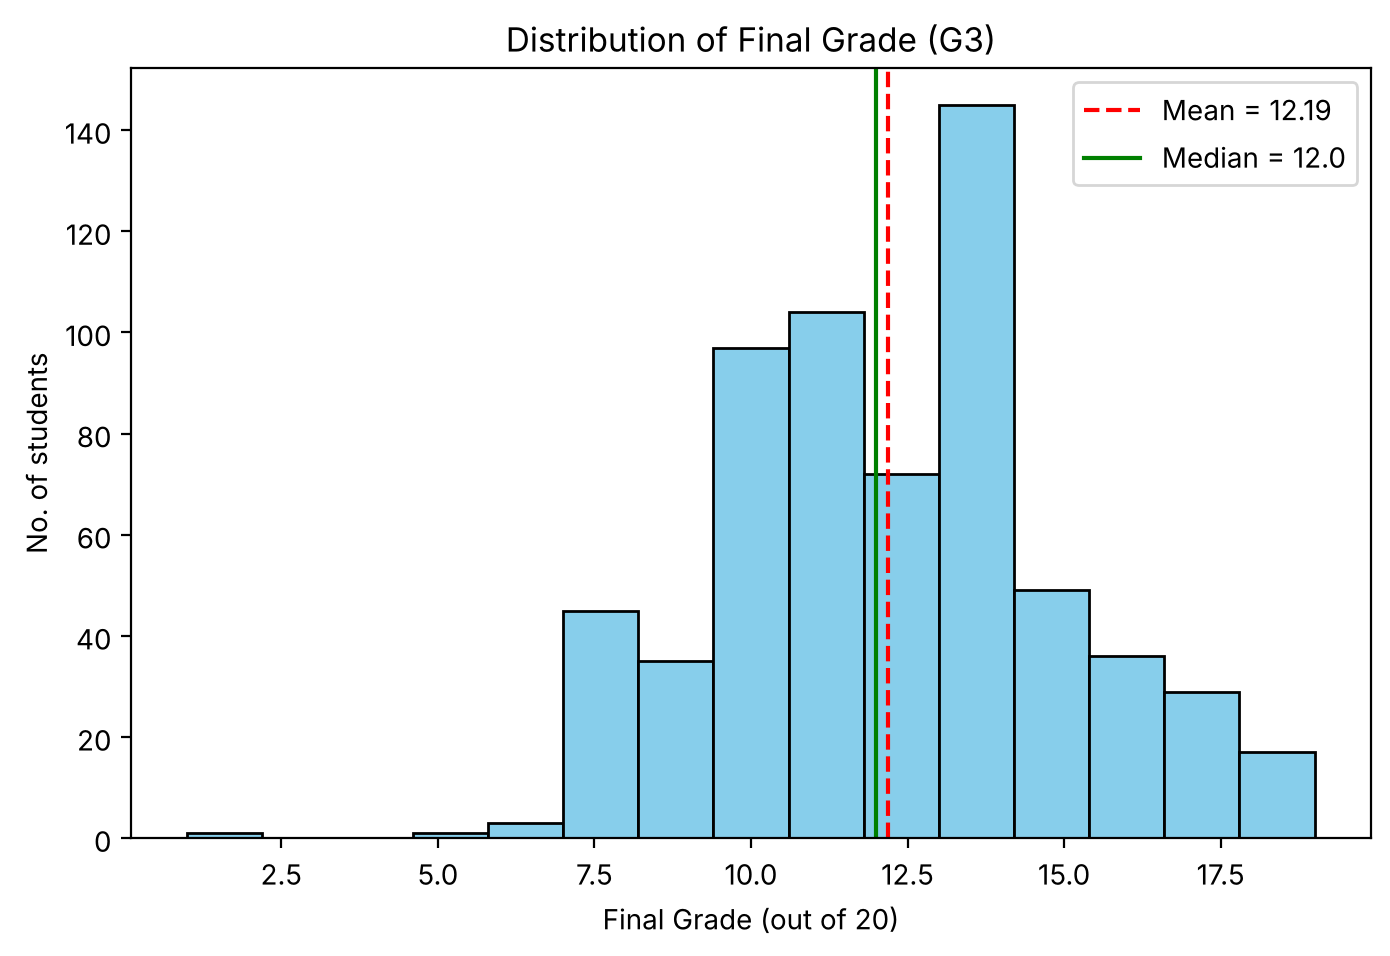

In [16]:
plt.figure(figsize=(8, 5))
plt.hist(data['G3'], bins=15, color='skyblue', edgecolor='black')
plt.axvline(data['G3'].mean(), color='red', linestyle='--', label='Mean = ' + str(round(data['G3'].mean(), 2)))
plt.axvline(data['G3'].median(), color='green', linestyle='-', label='Median = ' + str(data['G3'].median()))
plt.title('Distribution of Final Grade (G3)')
plt.xlabel('Final Grade (out of 20)')
plt.ylabel('No. of students')
plt.legend()
plt.savefig('plot_g3_hist.png', dpi=120, bbox_inches='tight')
plt.show()

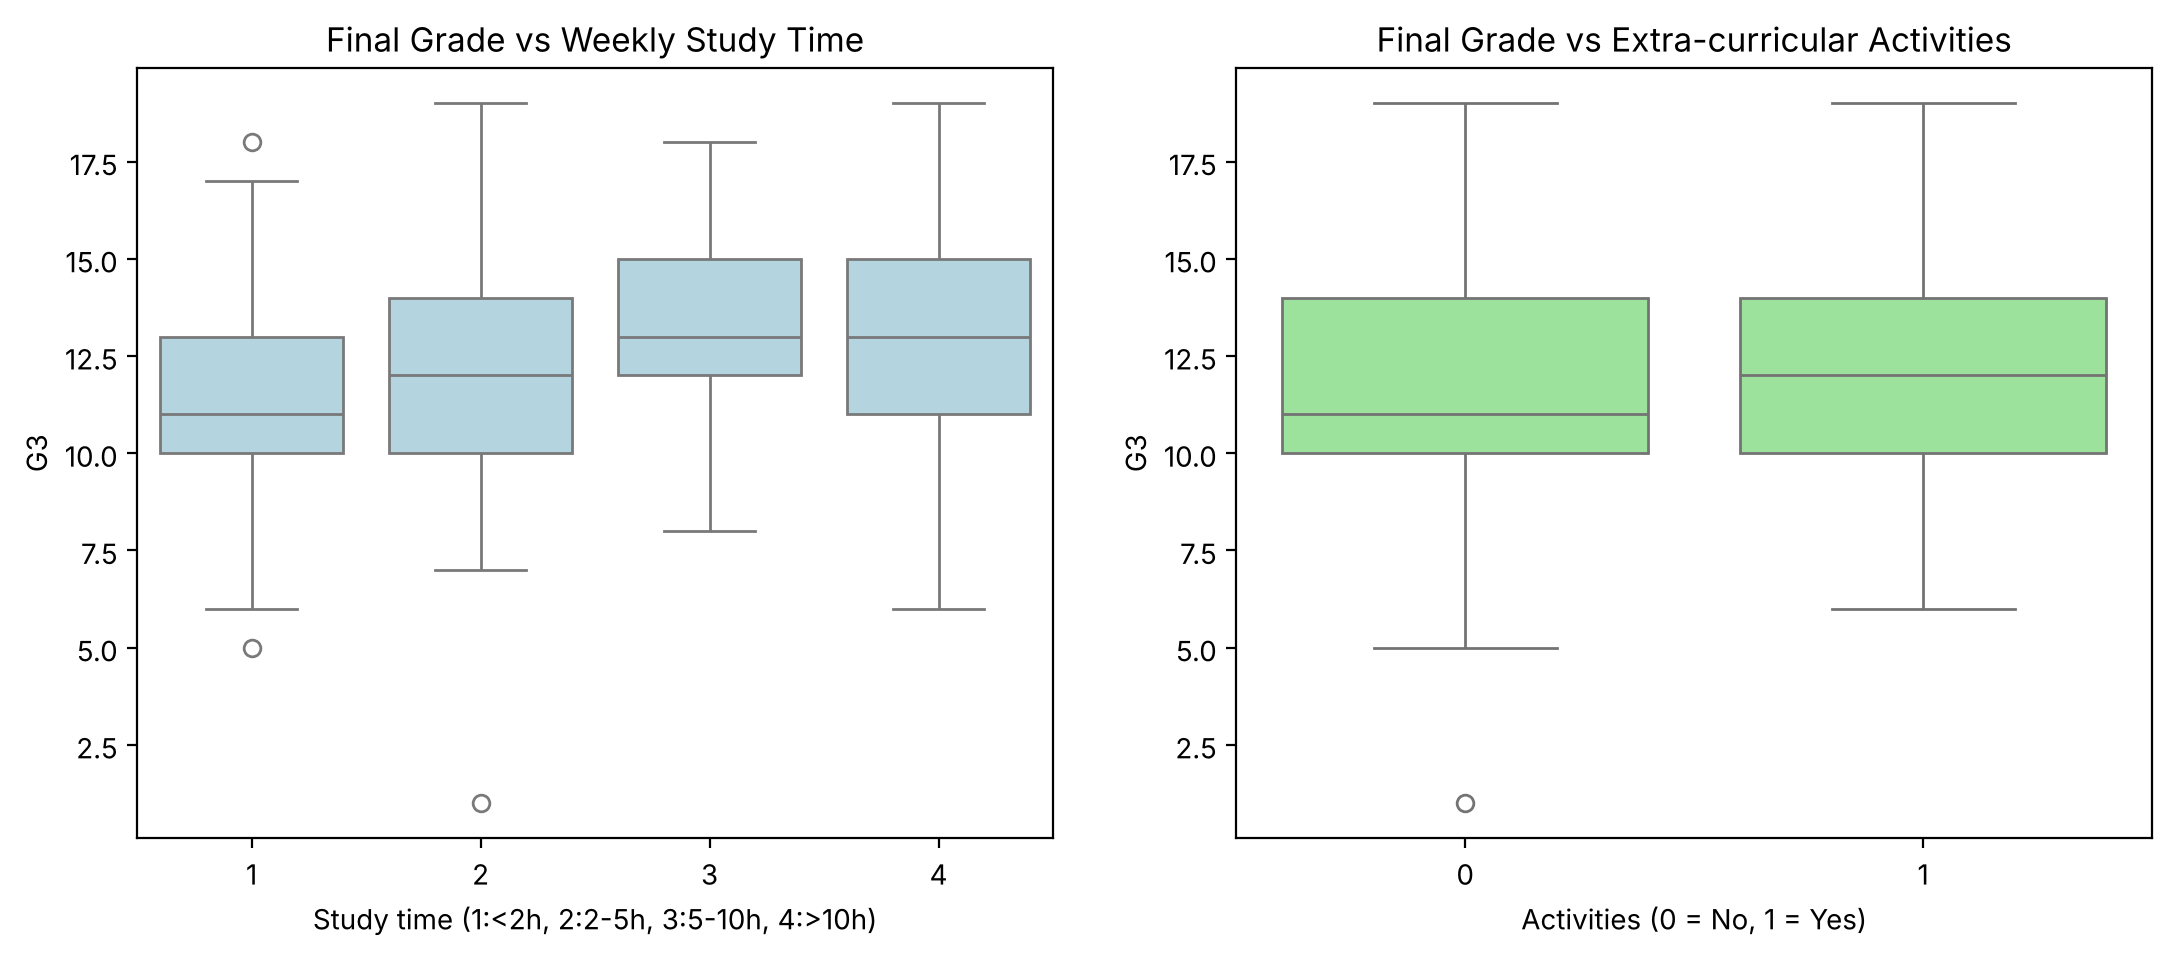

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
sns.boxplot(x='studytime', y='G3', data=data, ax=ax[0], color='lightblue')
ax[0].set_title('Final Grade vs Weekly Study Time')
ax[0].set_xlabel('Study time (1:<2h, 2:2-5h, 3:5-10h, 4:>10h)')
sns.boxplot(x='activities', y='G3', data=data, ax=ax[1], color='lightgreen')
ax[1].set_title('Final Grade vs Extra-curricular Activities')
ax[1].set_xlabel('Activities (0 = No, 1 = Yes)')
plt.savefig('plot_boxplots.png', dpi=120, bbox_inches='tight')
plt.show()

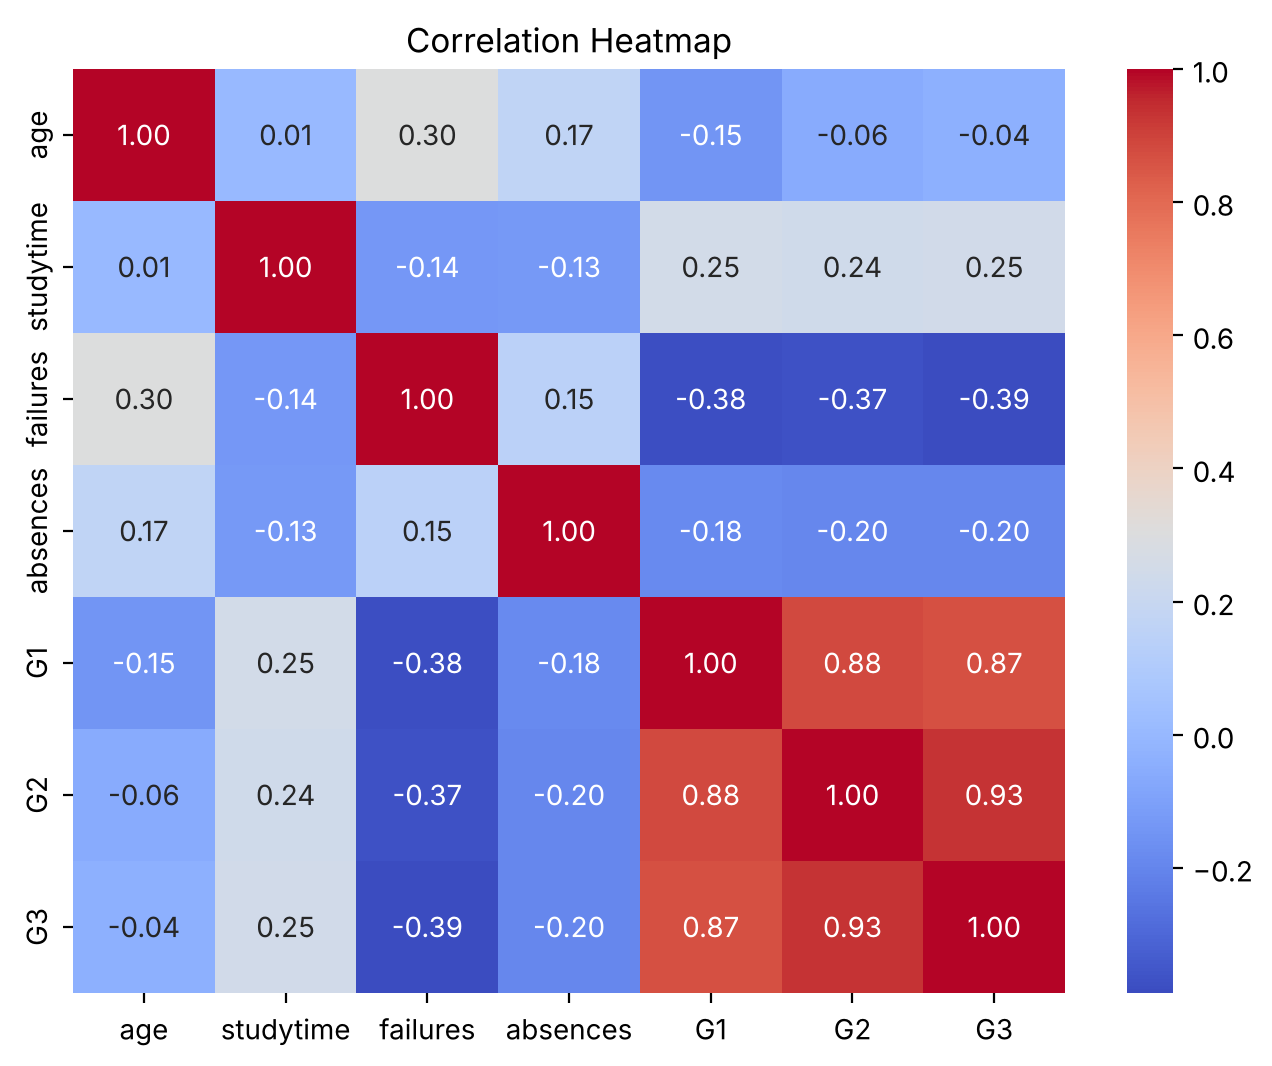

In [18]:
plt.figure(figsize=(8, 6))
sns.heatmap(corr_mat, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap')
plt.savefig('plot_heatmap.png', dpi=120, bbox_inches='tight')
plt.show()

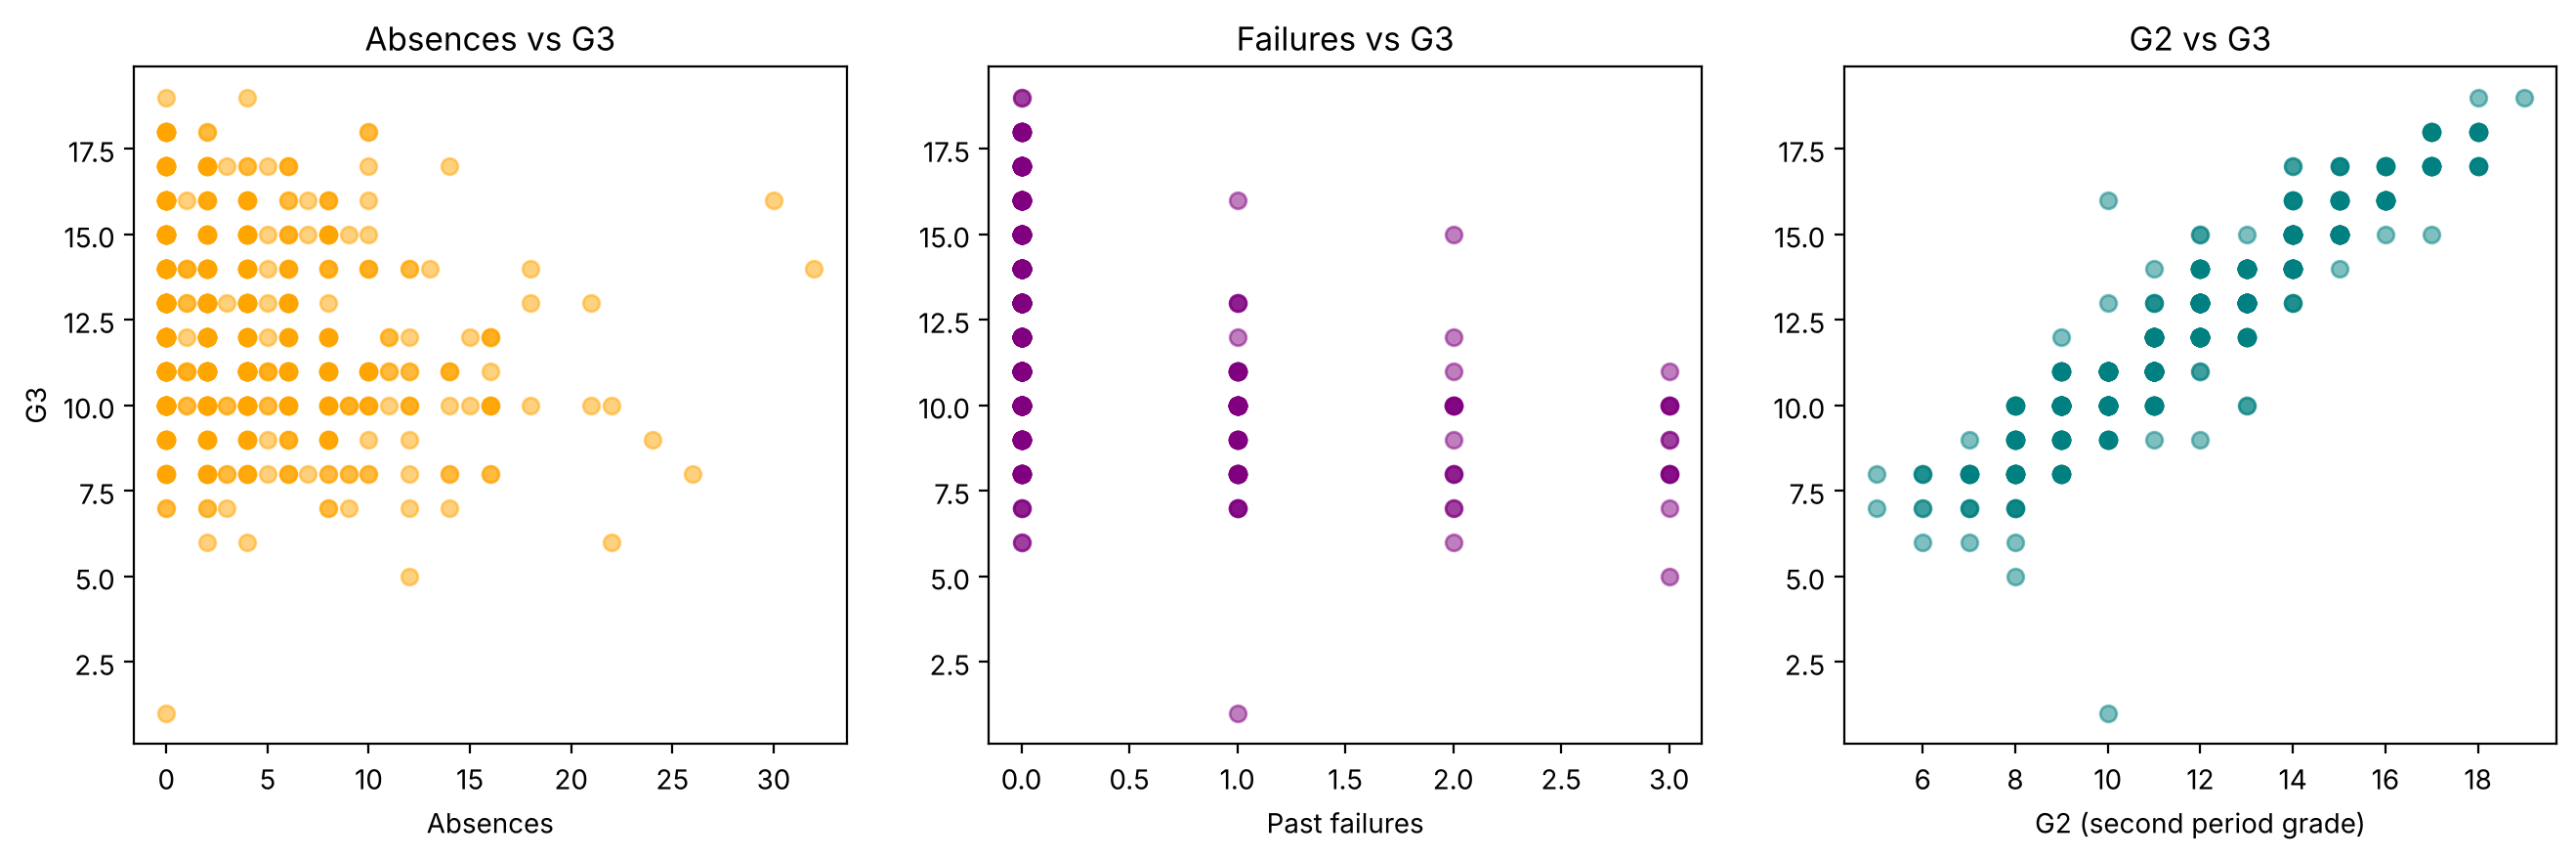

In [19]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
ax[0].scatter(data['absences'], data['G3'], alpha=0.5, color='orange')
ax[0].set_xlabel('Absences')
ax[0].set_ylabel('G3')
ax[0].set_title('Absences vs G3')
ax[1].scatter(data['failures'], data['G3'], alpha=0.5, color='purple')
ax[1].set_xlabel('Past failures')
ax[1].set_title('Failures vs G3')
ax[2].scatter(data['G2'], data['G3'], alpha=0.5, color='teal')
ax[2].set_xlabel('G2 (second period grade)')
ax[2].set_title('G2 vs G3')
plt.savefig('plot_scatter.png', dpi=120, bbox_inches='tight')
plt.show()

## 4. Confidence Interval
> *Requirement: calculate and interpret at least one 95% confidence interval.*

CI = x̄ ± t(α/2, n−1) × s/√n

**Why t and not z:** the population SD σ is unknown, so the exact method is the t-distribution with n−1 degrees of freedom. With n = 200 the t value (1.972) is almost the same as z (1.960).

In [20]:
x = strat['G3']
n = len(x)
xbar = x.mean()
s = x.std()
se = s / np.sqrt(n)
t_crit = stats.t.ppf(0.975, df=n - 1)
lower = xbar - t_crit * se
upper = xbar + t_crit * se

print("Sample mean =", round(xbar, 3), ", sample SD =", round(s, 3), ", n =", n)
print("t critical  =", round(t_crit, 3), " (z would be", round(stats.norm.ppf(0.975), 3), ")")
print("95% CI for mean final grade = (", round(lower, 3), ",", round(upper, 3), ")")
print("True population mean =", round(data['G3'].mean(), 3))
if lower <= data['G3'].mean() <= upper:
    print("-> population mean lies inside the CI")

Sample mean = 11.995 , sample SD = 2.737 , n = 200
t critical  = 1.972  (z would be 1.96 )
95% CI for mean final grade = ( 11.613 , 12.377 )
True population mean = 12.188
-> population mean lies inside the CI


In [21]:
# 95% CI of G3 for students with and without extra-curricular activities
for val in [0, 1]:
    g = data[data['activities'] == val]['G3']
    m = g.mean()
    e = stats.t.ppf(0.975, len(g) - 1) * g.std() / np.sqrt(len(g))
    print("activities =", val, "| n =", len(g), "| mean =", round(m, 3), "| 95% CI = (", round(m - e, 3), ",", round(m + e, 3), ")")

activities = 0 | n = 327 | mean = 11.969 | 95% CI = ( 11.668 , 12.271 )
activities = 1 | n = 307 | mean = 12.42 | 95% CI = ( 12.129 , 12.711 )


**Interpretation:** we are 95% confident that the true average final grade is between **11.61 and 12.38**. The real population mean (12.19) is inside the interval, so the stratified sample gave a good estimate.

## 5. Hypothesis Testing
> *Requirement: at least one Z-test or t-test; include ANOVA when applicable.*

Significance level **α = 0.05** for all tests.

| Question | Test | Why this test |
|---|---|---|
| Is average grade = 12? | One-sample Z-test | One sample vs a claimed value, n = 200 > 30 |
| Activities vs no activities | Independent t-test | Two different groups of students |
| Higher-edu yes vs no | Welch t-test | Two groups with unequal variances |
| G1 vs G3 | Paired t-test | Two grades of the same student |
| 4 study-time groups | One-way ANOVA | More than 2 groups |
| Failures 0/1/2/3 | One-way ANOVA + Kruskal-Wallis | More than 2 groups, unequal variances |

### 5.1 One-sample Z-test
Claim: the average final grade is **12** out of 20. H0: μ = 12, H1: μ ≠ 12.

We test on the **sample**, not on all 634 students, because on the full population the mean is already known and there is nothing to test.

In [22]:
mu0 = 12
x = strat['G3']
z = (x.mean() - mu0) / (x.std() / np.sqrt(len(x)))
p = 2 * (1 - stats.norm.cdf(abs(z)))
print("Z statistic =", round(z, 4))
print("p-value     =", round(p, 4))
if p < 0.05:
    print("Reject H0")
else:
    print("Fail to reject H0 -> no evidence that average final grade is different from 12")

# same check with one-sample t-test
t1, p1 = stats.ttest_1samp(x, mu0)
print("\n(check) one-sample t-test: t =", round(t1, 4), ", p =", round(p1, 4))

Z statistic = -0.0258
p-value     = 0.9794
Fail to reject H0 -> no evidence that average final grade is different from 12

(check) one-sample t-test: t = -0.0258 , p = 0.9794


### 5.2 Independent two-sample t-test – activities
H0: μ(activities) = μ(no activities), H1: they are different.

First we check equal variances with **Levene's test**: if p > 0.05 we use the normal (pooled) t-test, otherwise Welch's t-test.

In [23]:
g_yes = data[data['activities'] == 1]['G3']
g_no = data[data['activities'] == 0]['G3']
print("Mean G3 activities yes:", round(g_yes.mean(), 3), " n =", len(g_yes))
print("Mean G3 activities no :", round(g_no.mean(), 3), " n =", len(g_no))

lev = stats.levene(g_yes, g_no)
print("Levene p-value =", round(lev.pvalue, 4))
eq = lev.pvalue > 0.05

t_stat, p_val = stats.ttest_ind(g_yes, g_no, equal_var=eq)
print("t statistic =", round(t_stat, 4), ", p-value =", round(p_val, 4))
if p_val < 0.05:
    print("Reject H0 -> significant difference")
else:
    print("Fail to reject H0")

Mean G3 activities yes: 12.42  n = 307
Mean G3 activities no : 11.969  n = 327
Levene p-value = 0.487
t statistic = 2.113 , p-value = 0.035
Reject H0 -> significant difference


### 5.3 Welch t-test – wants higher education
Here the groups are very unequal (570 vs 64) and Levene's test fails, so we use **Welch's t-test** (`equal_var=False`).

In [24]:
h_yes = data[data['higher'] == 1]['G3']
h_no = data[data['higher'] == 0]['G3']
print("Mean G3 wants higher edu:", round(h_yes.mean(), 3), " n =", len(h_yes))
print("Mean G3 does not want   :", round(h_no.mean(), 3), " n =", len(h_no))
print("Levene p-value =", stats.levene(h_yes, h_no).pvalue)
t_stat, p_val = stats.ttest_ind(h_yes, h_no, equal_var=False)
print("Welch t =", round(t_stat, 4), ", p-value =", p_val)
if p_val < 0.05:
    print("Reject H0 -> significant difference")

Mean G3 wants higher edu: 12.491  n = 570
Mean G3 does not want   : 9.484  n = 64
Levene p-value = 6.872899123866658e-05
Welch t = 12.5284 , p-value = 3.460764583639654e-22
Reject H0 -> significant difference


### 5.4 Paired t-test – G1 vs G3
The same student has both grades, so the two samples are **related** → paired t-test (an independent test would be wrong here).
H0: mean of (G3 − G1) = 0.

In [25]:
diff = data['G3'] - data['G1']
print("Mean G1 =", round(data['G1'].mean(), 3), ", mean G3 =", round(data['G3'].mean(), 3))
print("Mean difference (G3 - G1) =", round(diff.mean(), 3))
t_stat, p_val = stats.ttest_rel(data['G3'], data['G1'])
print("t statistic =", round(t_stat, 4), ", p-value =", p_val)
if p_val < 0.05:
    print("Reject H0 -> grades changed significantly from G1 to G3")

Mean G1 = 11.502 , mean G3 = 12.188
Mean difference (G3 - G1) = 0.686
t statistic = 12.4313 , p-value = 6.707419786545427e-32
Reject H0 -> grades changed significantly from G1 to G3


### 5.5 One-way ANOVA – study time
4 groups, so we use ANOVA instead of doing many t-tests (many t-tests increase the chance of a false result).
H0: μ1 = μ2 = μ3 = μ4.

ANOVA assumes (1) normal groups and (2) equal variances, so we check both. If an assumption fails we confirm with **Kruskal-Wallis** (the non-parametric version of ANOVA, which does not need these assumptions).

In [26]:
print(data.groupby('studytime')['G3'].agg(['count', 'mean', 'std']).round(3))
groups = [data[data['studytime'] == i]['G3'] for i in [1, 2, 3, 4]]
f_stat, p_val = stats.f_oneway(groups[0], groups[1], groups[2], groups[3])
print("\nF statistic =", round(f_stat, 4), ", p-value =", p_val)
if p_val < 0.05:
    print("Reject H0 -> study time groups have different mean grades")

           count    mean    std
studytime                      
1            204  11.270  2.440
2            298  12.376  2.690
3             97  13.227  2.502
4             35  13.057  3.038

F statistic = 15.4167 , p-value = 1.0894029320163948e-09
Reject H0 -> study time groups have different mean grades


In [27]:
print("Levene (equal variance) p-value =", round(stats.levene(*groups).pvalue, 4))
for i in range(4):
    print("Shapiro (normality) studytime =", i + 1, ": p-value =", round(stats.shapiro(groups[i]).pvalue, 4))
print("Kruskal-Wallis p-value =", stats.kruskal(*groups).pvalue)

Levene (equal variance) p-value = 0.083
Shapiro (normality) studytime = 1 : p-value = 0.0002
Shapiro (normality) studytime = 2 : p-value = 0.0
Shapiro (normality) studytime = 3 : p-value = 0.0249
Shapiro (normality) studytime = 4 : p-value = 0.1659
Kruskal-Wallis p-value = 6.980859418387785e-10


### 5.6 One-way ANOVA – past failures

In [28]:
print(data.groupby('failures')['G3'].agg(['count', 'mean']).round(3))
groups2 = [data[data['failures'] == i]['G3'] for i in [0, 1, 2, 3]]
f_stat, p_val = stats.f_oneway(*groups2)
print("\nF statistic =", round(f_stat, 4), ", p-value =", p_val)
print("Levene p-value =", round(stats.levene(*groups2).pvalue, 4))
print("Kruskal-Wallis p-value =", stats.kruskal(*groups2).pvalue)

          count    mean
failures               
0           543  12.648
1            63   9.603
2            15   9.400
3            13   8.692

F statistic = 45.1343 , p-value = 1.97719322053251e-26
Levene p-value = 0.0003
Kruskal-Wallis p-value = 2.2881237894717597e-25


**Interpretation of all tests:**
- Z-test: p = 0.979 → we cannot reject the claim that the average grade is 12.
- Activities: p = 0.035 → significant, but the difference is small (12.42 vs 11.97, only 0.45 marks).
- Higher education: p ≈ 3.5e−22 → students who want higher studies score about 3 marks more.
- Paired: p ≈ 6.7e−32 → grades improved significantly from G1 (11.50) to G3 (12.19).
- Study time: F = 15.42, p ≈ 1.1e−9 → grade increases with study time (11.27 → 13.23).
- Failures: F = 45.13, p ≈ 2e−26 → students with past failures score about 3 marks less.
- Assumptions: study time variances are equal (Levene p = 0.083) but some groups are not normal; failures variances are not equal (p = 0.0003). Kruskal-Wallis gives the same answer in both cases, so the conclusions do not change.

## 6. Correlation
> *Requirement: Pearson or Spearman correlation analysis with interpretation.*

**Why both:** Pearson measures straight-line relationship. Spearman uses ranks, so it is better for ordinal variables (studytime, failures) and skewed variables (absences). If both give the same picture, our conclusion is reliable. (For 0/1 variables Pearson is the point-biserial correlation.)

In [29]:
res = []
for c in ['age', 'studytime', 'failures', 'absences', 'activities', 'higher', 'internet', 'G1', 'G2']:
    r, p1 = stats.pearsonr(data[c], data['G3'])
    rho, p2 = stats.spearmanr(data[c], data['G3'])
    res.append([c, round(r, 3), round(p1, 4), round(rho, 3), round(p2, 4)])

corr_table = pd.DataFrame(res, columns=['Variable', 'Pearson r', 'Pearson p', 'Spearman rho', 'Spearman p'])
corr_table = corr_table.sort_values('Pearson r', key=abs, ascending=False)
corr_table

,Variable,Pearson r,Pearson p,Spearman rho,Spearman p
8,G2,0.934,0.0000,0.941,0.0000
7,G1,0.866,0.0000,0.879,0.0000
2,failures,-0.388,0.0000,-0.431,0.0000
5,higher,0.337,0.0000,0.347,0.0000
1,studytime,0.246,0.0000,0.264,0.0000
3,absences,-0.196,0.0000,-0.214,0.0000
6,internet,0.126,0.0015,0.142,0.0003
4,activities,0.084,0.0350,0.090,0.0234
0,age,-0.038,0.3393,-0.030,0.4441


**Interpretation** (|r| < 0.3 weak, 0.3–0.7 moderate, > 0.7 strong):
- G2 (0.93) and G1 (0.87): strong positive – earlier marks predict final marks.
- Failures (−0.39): moderate negative; higher (0.34): moderate positive.
- Study time (0.25) weak positive; absences (−0.20) weak negative; activities (0.08) very weak.
- All are significant (p < 0.05) except age. Pearson and Spearman agree.

## 7. Regression
> *Requirement: Simple Linear Regression mandatory; Multiple Linear Regression encouraged.*

**Train/test split:** 80% train (507 students), 20% test (127 students), `random_state=42` so results are the same every time we run. The test set is never used for fitting – it acts as unseen data.

**Models we built and why:**
1. **SLR: G2 → G3** – G2 has the highest correlation with G3, so it is the best single predictor.
2. **SLR: studytime → G3** – to see how much one participation variable alone can explain.
3. **MLR Model A: participation only** (studytime, failures, absences, activities, higher, internet) – answers our main question.
4. **MLR Model B: participation + G1, G2** – the best possible prediction.

In [30]:
y = data['G3']
part_cols = ['studytime', 'failures', 'absences', 'activities', 'higher', 'internet']
full_cols = part_cols + ['G1', 'G2']

# same random_state -> same students in the test set for every model
train_idx, test_idx = train_test_split(data.index, test_size=0.2, random_state=42)
print("Train size:", len(train_idx), " Test size:", len(test_idx))
y_train = y[train_idx]
y_test = y[test_idx]

Train size: 507  Test size: 127


In [31]:
# 7.1 SLR : G2 -> G3
slr = LinearRegression()
slr.fit(data.loc[train_idx, ['G2']], y_train)
print("SLR equation: G3 =", round(slr.intercept_, 3), "+", round(slr.coef_[0], 3), "x G2")

# 7.2 SLR : studytime -> G3
slr2 = LinearRegression()
slr2.fit(data.loc[train_idx, ['studytime']], y_train)
print("SLR equation: G3 =", round(slr2.intercept_, 3), "+", round(slr2.coef_[0], 3), "x studytime")

# 7.3 MLR Model A
mlrA = LinearRegression()
mlrA.fit(data.loc[train_idx, part_cols], y_train)

# 7.4 MLR Model B
mlrB = LinearRegression()
mlrB.fit(data.loc[train_idx, full_cols], y_train)

coef = pd.DataFrame({'Model A coef': pd.Series(mlrA.coef_, index=part_cols),
                     'Model B coef': pd.Series(mlrB.coef_, index=full_cols)})
coef = coef.loc[full_cols]
coef.loc['intercept'] = [mlrA.intercept_, mlrB.intercept_]
coef.round(4)

SLR equation: G3 = 0.979 + 0.956 x G2
SLR equation: G3 = 10.566 + 0.835 x studytime


,Model A coef,Model B coef
studytime,0.5555,0.0773
failures,-1.3689,-0.1008
absences,-0.1026,-0.0108
activities,0.2022,0.0139
higher,1.8262,0.0912
internet,0.5084,0.0396
G1,NaN,0.1916
G2,NaN,0.7587
intercept,9.5960,0.8847


**Meaning of coefficients:**
- SLR: every 1 mark more in G2 → about 0.96 marks more in G3.
- Model A: wanting higher education adds about 1.83 marks, each past failure reduces about 1.37 marks, each study-time level adds about 0.56 marks, each absence reduces about 0.10 marks.
- In Model B the participation coefficients become small because G1 and G2 already contain their effect (students who participate more already have higher G1, G2).

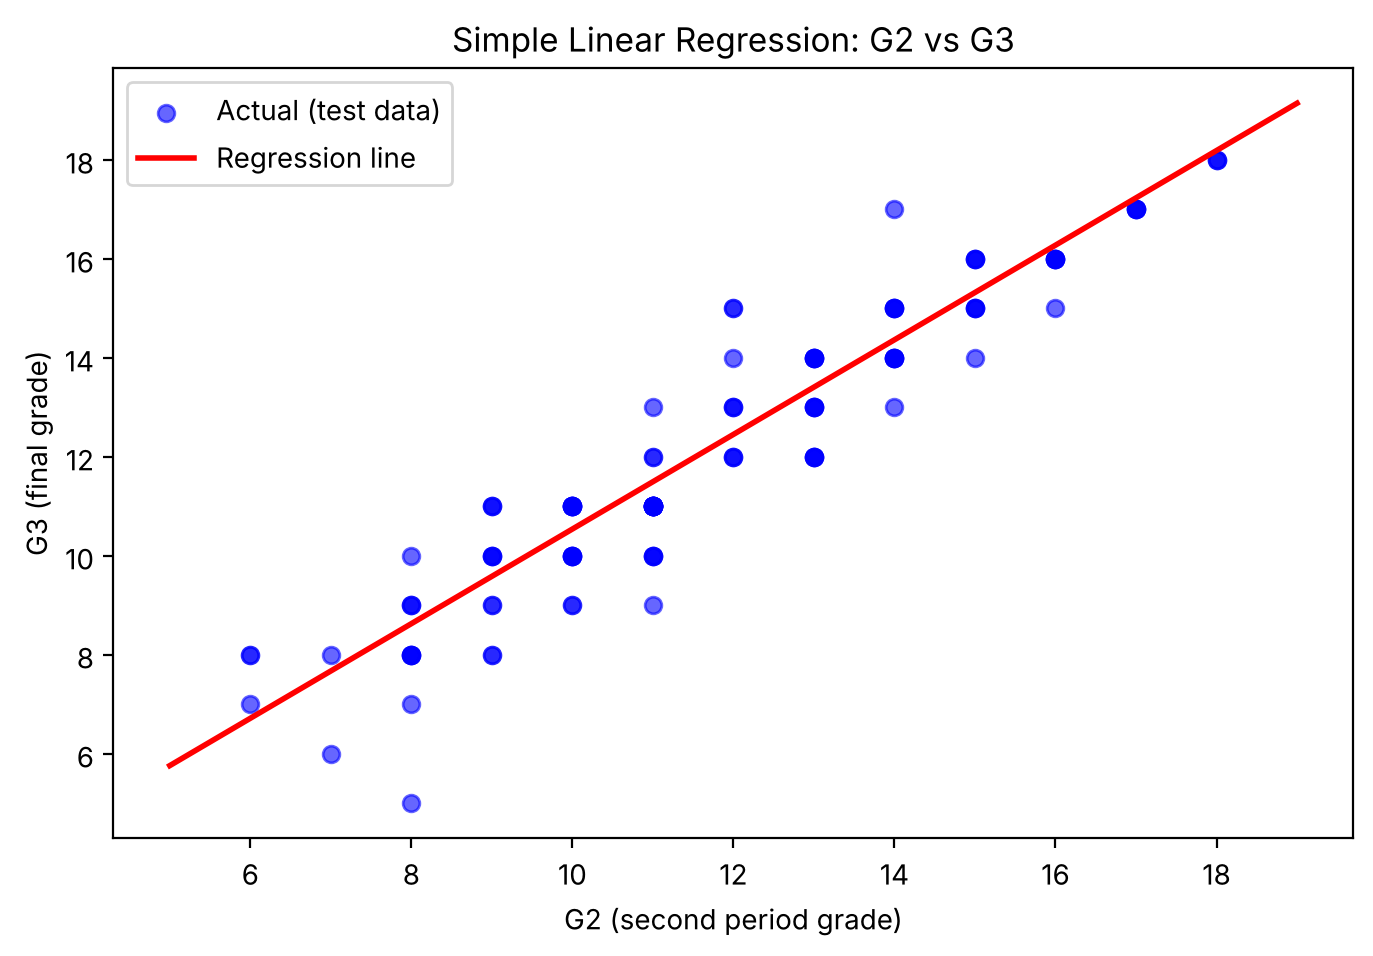

In [32]:
plt.figure(figsize=(8, 5))
plt.scatter(data.loc[test_idx, 'G2'], y_test, color='blue', alpha=0.6, label='Actual (test data)')
xs = pd.DataFrame({'G2': np.linspace(data['G2'].min(), data['G2'].max(), 100)})
plt.plot(xs['G2'], slr.predict(xs), color='red', linewidth=2, label='Regression line')
plt.xlabel('G2 (second period grade)')
plt.ylabel('G3 (final grade)')
plt.title('Simple Linear Regression: G2 vs G3')
plt.legend()
plt.savefig('plot_slr.png', dpi=120, bbox_inches='tight')
plt.show()

### 7.5 Checking regression assumptions (Model B)
| Assumption | How we check |
|---|---|
| Linearity and equal variance | Residuals vs fitted plot should show no pattern |
| Normal residuals | Shapiro-Wilk test, skewness |
| Independent residuals | Durbin-Watson (≈ 2 is good) |
| No multicollinearity | VIF (< 5 is acceptable) |

In [33]:
train_resid = y_train - mlrB.predict(data.loc[train_idx, full_cols])
print("Mean of residuals =", round(train_resid.mean(), 6))
print("Skewness of residuals =", round(stats.skew(train_resid), 4))
print("Shapiro-Wilk p-value =", stats.shapiro(train_resid).pvalue)
print("Durbin-Watson =", round(durbin_watson(train_resid), 4))

Xc = sm.add_constant(data.loc[train_idx, full_cols])
print("\nVIF values:")
for i in range(1, Xc.shape[1]):
    print("  ", Xc.columns[i], "=", round(variance_inflation_factor(Xc.values, i), 2))

Mean of residuals = 0.0
Skewness of residuals = -1.8548
Shapiro-Wilk p-value = 4.5558831741190705e-21
Durbin-Watson = 1.9671

VIF values:
   studytime = 1.08
   failures = 1.21
   absences = 1.08
   activities = 1.02
   higher = 1.18
   internet = 1.04
   G1 = 4.62
   G2 = 4.52


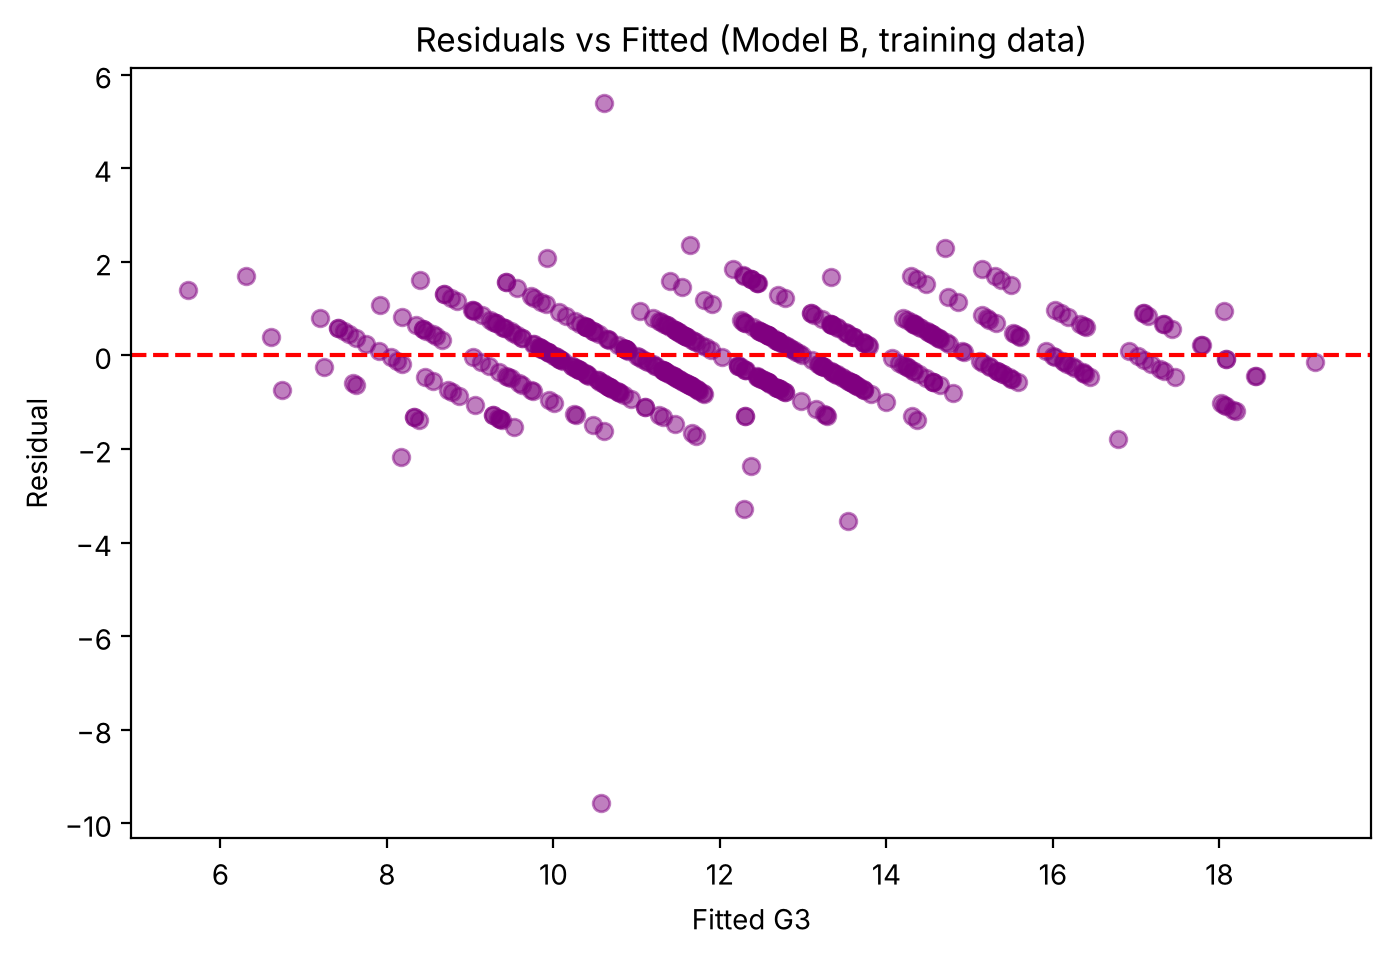

In [34]:
plt.figure(figsize=(8, 5))
plt.scatter(mlrB.predict(data.loc[train_idx, full_cols]), train_resid, alpha=0.5, color='purple')
plt.axhline(0, color='red', linestyle='--')
plt.xlabel('Fitted G3')
plt.ylabel('Residual')
plt.title('Residuals vs Fitted (Model B, training data)')
plt.savefig('plot_resid_fitted.png', dpi=120, bbox_inches='tight')
plt.show()

**Result:** Durbin-Watson = 1.97 (independent) and VIF < 5 for all features (G1 and G2 ≈ 4.6 because they are correlated with each other). Residuals are left-skewed (Shapiro p < 0.05): a few weak students score much lower in the final than G1/G2 suggest, so the model over-predicts for them. Predictions on average are still good.

## 8. Model Evaluation
> *Requirement: MAE, MSE, RMSE and R².*

All metrics are calculated on the **test set only** (unseen data), so they show real prediction performance.

- **MAE** – average absolute error in marks (easy to understand)
- **MSE** – average squared error (punishes big errors more)
- **RMSE** – √MSE, back in marks
- **R²** – fraction of variation in G3 explained by the model (1 = perfect)

In [35]:
def show_metrics(y_true, y_pred, name):
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)
    return [name, mae, mse, rmse, r2]

pred_slr = slr.predict(data.loc[test_idx, ['G2']])
pred_slr2 = slr2.predict(data.loc[test_idx, ['studytime']])
pred_A = mlrA.predict(data.loc[test_idx, part_cols])
pred_B = mlrB.predict(data.loc[test_idx, full_cols])

results = pd.DataFrame([show_metrics(y_test, pred_slr, 'SLR (G2)'),
                        show_metrics(y_test, pred_slr2, 'SLR (studytime)'),
                        show_metrics(y_test, pred_A, 'MLR A (participation)'),
                        show_metrics(y_test, pred_B, 'MLR B (participation + G1, G2)')],
                       columns=['Model', 'MAE', 'MSE', 'RMSE', 'R2'])
results.round(4)

,Model,MAE,MSE,RMSE,R2
0,SLR (G2),0.7528,0.9153,0.9567,0.8883
1,SLR (studytime),2.3675,7.9509,2.8197,0.0299
2,MLR A (participation),2.2033,6.9739,2.6408,0.1491
3,"MLR B (participation + G1, G2)",0.7413,0.8641,0.9296,0.8946


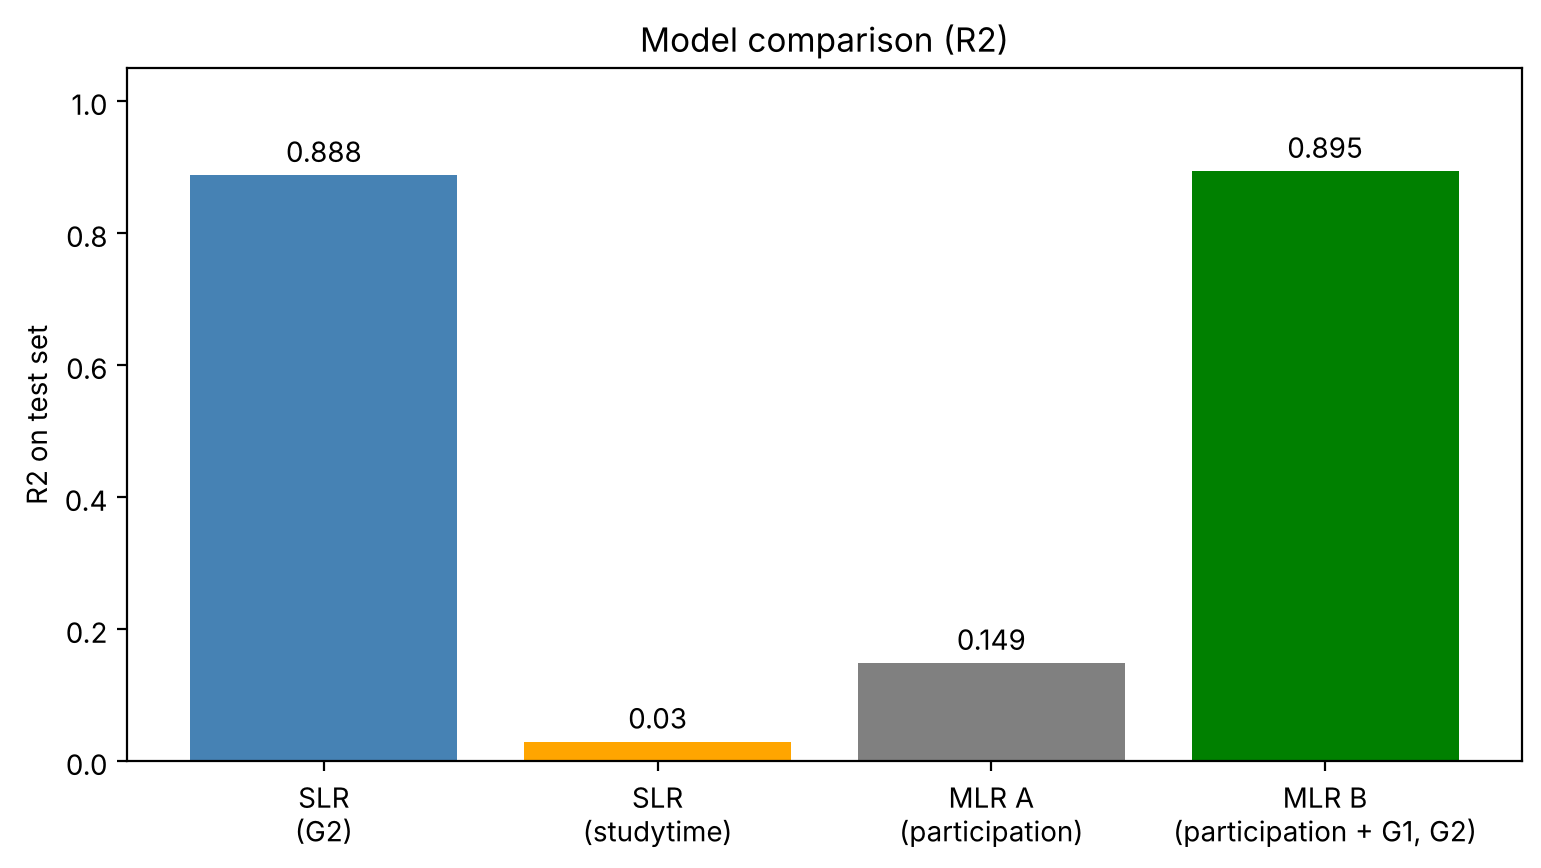

In [36]:
plt.figure(figsize=(9, 4.5))
labels = ['SLR\n(G2)', 'SLR\n(studytime)', 'MLR A\n(participation)', 'MLR B\n(participation + G1, G2)']
plt.bar(labels, results['R2'], color=['steelblue', 'orange', 'gray', 'green'])
for i in range(len(labels)):
    plt.text(i, results['R2'][i] + 0.02, str(round(results['R2'][i], 3)), ha='center')
plt.ylabel('R2 on test set')
plt.title('Model comparison (R2)')
plt.ylim(0, 1.05)
plt.savefig('plot_r2_compare.png', dpi=120, bbox_inches='tight')
plt.show()

**Interpretation:**
- Participation alone (Model A) explains only about 15% of the variation (R² = 0.149, error ≈ 2.2 marks).
- Study time alone explains only 3%.
- Adding G1 and G2 (Model B) gives R² = 0.895 and MAE = 0.74 marks out of 20 – the best model.
- SLR with G2 alone is almost as good (R² = 0.888), so G2 carries most of the information.

## 9. Prediction on Unseen Data
> *Requirement: predict outcomes for unseen data using a held-out test set.*

In [37]:
pred_table = pd.DataFrame({'Actual G3': y_test.values[:10],
                           'Predicted (SLR G2)': np.round(pred_slr[:10], 2),
                           'Predicted (MLR B)': np.round(pred_B[:10], 2),
                           'Error (MLR B)': np.round(y_test.values[:10] - pred_B[:10], 2)})
pred_table

,Actual G3,Predicted (SLR G2),Predicted (MLR B),Error (MLR B)
0,14,12.45,11.99,2.01
1,12,12.45,12.66,-0.66
2,15,15.32,15.19,-0.19
3,15,12.45,12.57,2.43
4,13,14.37,14.28,-1.28
5,10,10.54,10.06,-0.06
6,14,13.41,13.08,0.92
7,9,9.59,9.70,-0.70
8,12,13.41,13.32,-1.32
9,15,14.37,14.47,0.53


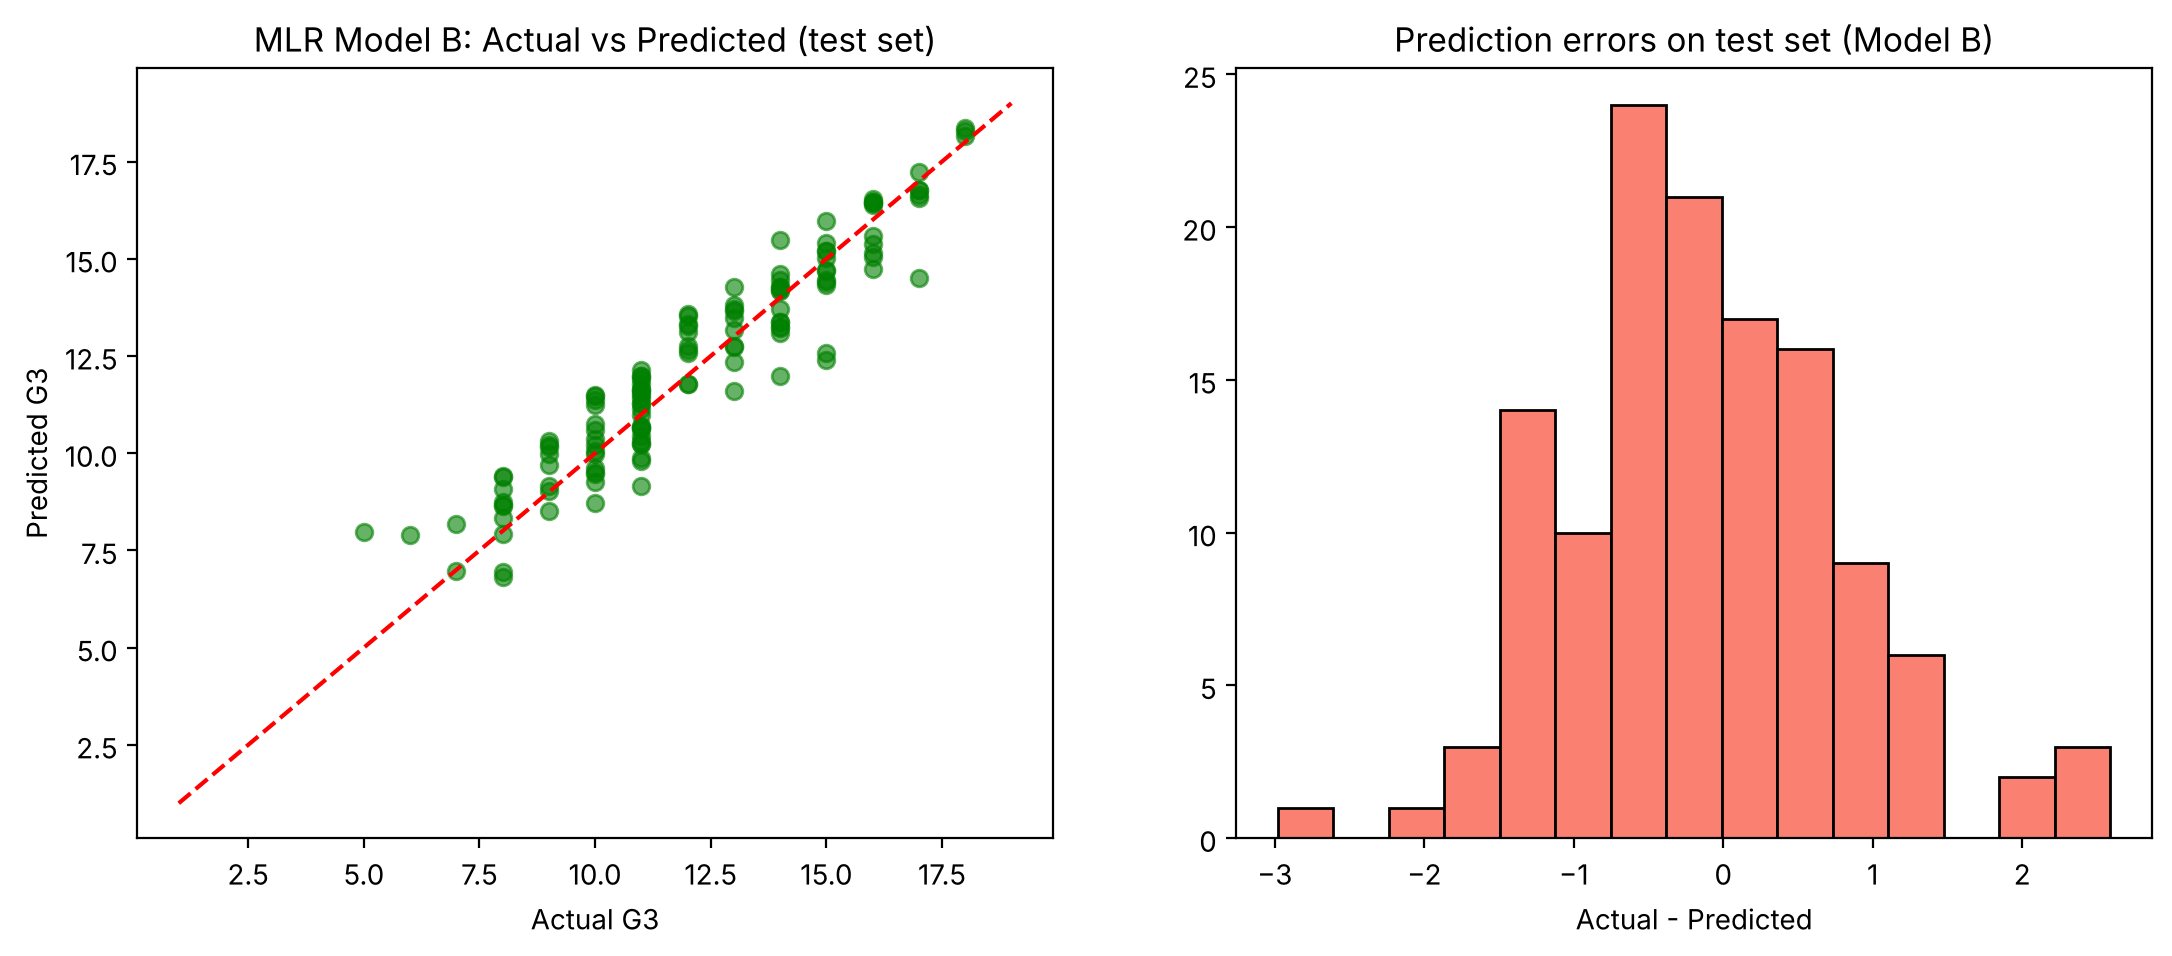

In [38]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].scatter(y_test, pred_B, color='green', alpha=0.6)
ax[0].plot([y.min(), y.max()], [y.min(), y.max()], 'r--')
ax[0].set_xlabel('Actual G3')
ax[0].set_ylabel('Predicted G3')
ax[0].set_title('MLR Model B: Actual vs Predicted (test set)')
ax[1].hist(y_test - pred_B, bins=15, color='salmon', edgecolor='black')
ax[1].set_title('Prediction errors on test set (Model B)')
ax[1].set_xlabel('Actual - Predicted')
plt.savefig('plot_mlr.png', dpi=120, bbox_inches='tight')
plt.show()

In [39]:
# 3 new (made up) students
new_students = pd.DataFrame({
    'studytime': [1, 3, 2],
    'failures': [2, 0, 0],
    'absences': [14, 2, 6],
    'activities': [0, 1, 1],
    'higher': [0, 1, 1],
    'internet': [1, 1, 0],
    'G1': [8, 15, 11],
    'G2': [8, 16, 12]
})
new_students['Predicted G3 (Model A)'] = np.round(mlrA.predict(new_students[part_cols]), 2)
new_students['Predicted G3 (Model B)'] = np.round(mlrB.predict(new_students[full_cols]), 2)
new_students

,studytime,failures,absences,activities,higher,internet,G1,G2,Predicted G3 (Model A),Predicted G3 (Model B)
0,1,2,14,0,0,1,8,8,6.48,8.25
1,3,0,2,1,1,1,15,16,13.59,16.25
2,2,0,6,1,1,0,11,12,12.12,12.29


## 10. Interpretation
> *Requirement: explain statistical significance, model accuracy, limitations and practical implications.*

**Statistical significance**
- Study time, wish for higher education, past failures and absences are all significantly related to the final grade (p < 0.05).
- Extra-curricular activities are significant (p = 0.035) but the effect is small (0.45 marks).
- Students improve significantly from G1 to G3.

**Model accuracy**
- Best model (MLR B): R² = 0.895, MAE = 0.74, RMSE = 0.93 on unseen test data.
- Participation only (MLR A): R² = 0.149 – participation matters, but it explains only a small part of the final grade by itself.

**Limitations**
- Only 2 Portuguese schools (2005–06); study time is self-reported in 4 categories.
- Correlation does not mean causation.
- G1 and G2 dominate the best model, so it mostly shows that past marks predict future marks.
- Residuals are left-skewed (the model over-predicts for very weak students); one suspicious G1 = 0 row was kept.

**Practical implications**
- Teachers can use first and second period marks to find weak students early.
- Students with past failures, many absences and low study time should be monitored.
- Encouraging 5+ hours of study per week and motivating students towards higher education can improve results.

## 11. What we did not do and why
| Not done | Reason |
|---|---|
| Use the other 21 columns (alcohol, family, parents' jobs…) | Not related to participation; more columns would make the model harder to explain without answering our question |
| Combine maths + Portuguese files | 382 students are in both files – they would be counted twice |
| Remove absence outliers | They are real students; attendance is a key variable |
| Remove the G1 = 0 row | Only 1 of 634 rows, does not change results; mentioned in limitations |
| Scale / normalise features | Linear regression does not need scaling to predict, and unscaled coefficients are easier to read (marks per unit) |
| Use Z-test on the whole 634 | Population mean is already known there, so a test has no meaning |
| ANOVA by school or sex | Only 2 groups – that is a t-test case, not ANOVA |
| Logistic regression / random forest / cross-validation | Outside our syllabus; the requirement asks for SLR and MLR |
| Log-transform absences | Kept the original units so the results are easy to explain; Spearman already handles the skew |